In [1]:
# SECTION 1: IMPORTS AND PROJECT PATHS

import pandas as pd
import numpy as np
import joblib
import json

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dengue_weather_weekly_25_districts.csv"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "forecasting"
    / "riskweave_final_dengue_forecasting_model.joblib"
)

MANIFEST_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "forecasting"
    / "riskweave_final_model_manifest.json"
)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Model exists:", MODEL_PATH.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Dataset exists: True
Model exists: True
Manifest exists: True


In [2]:
# SECTION 2: LOAD SELECTED MODEL AND DATASET

if not DATA_PATH.exists():
    raise FileNotFoundError(DATA_PATH)

if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

df = pd.read_csv(DATA_PATH)

df["week_start"] = pd.to_datetime(df["week_start"])
df["week_end"] = pd.to_datetime(df["week_end"])

df = df.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

final_model = joblib.load(MODEL_PATH)

print("Dataset shape:", df.shape)
print("Number of districts:", df["district_key"].nunique())
print("Latest reporting period:", df["week_start"].max())
print("Selected model loaded successfully.")

Dataset shape: (24775, 27)
Number of districts: 25
Latest reporting period: 2025-12-13 00:00:00
Selected model loaded successfully.


In [3]:
# SECTION 3: INSPECT MODEL MANIFEST

if MANIFEST_PATH.exists():

    with open(MANIFEST_PATH, "r") as file:
        manifest = json.load(file)

    print(json.dumps(manifest, indent=4))

else:
    print("Model manifest not found.")

{
    "project": "RiskWeave",
    "notebook": "06_dengue_case_forecasting.ipynb",
    "selected_model": "Histogram Gradient Boosting",
    "selected_feature_set": "Without weather",
    "forecast_origin": "Latest completed reporting period",
    "forecast_target": "Next reporting period dengue cases",
    "number_of_predictors": 12,
    "features": [
        "district_key",
        "dengue_current_period",
        "dengue_lag_1",
        "dengue_lag_2",
        "dengue_lag_3",
        "dengue_lag_4",
        "dengue_lag_51",
        "dengue_lag_52",
        "dengue_rolling_mean_4",
        "month",
        "week_sin",
        "week_cos"
    ],
    "training_rows": 17325,
    "validation_rows": 3700,
    "test_rows": 3725,
    "test_MAE": 12.384965664315903,
    "test_RMSE": 28.87209601424702,
    "weather_ablation_file": "weather_ablation_comparison.csv",
    "weather_features_improved_test_metrics": false,
    "weather_source_note": "Open-Meteo ERA5 weather data was evaluated in the a

In [4]:
# Check latest reporting period for each district

latest_by_district = (
    df.groupby("district_key")
    .agg(
        latest_week_start=("week_start", "max"),
        number_of_periods=("week_start", "nunique")
    )
    .reset_index()
)

print("Latest reporting period by district:")
display(latest_by_district)

print("\nNumber of districts:", latest_by_district["district_key"].nunique())

print(
    "\nDistricts with different latest reporting periods:",
    latest_by_district["latest_week_start"].nunique()
)

print("\nReporting period length distribution:")

df["period_length_days"] = (
    df["week_end"] - df["week_start"]
).dt.days + 1

display(
    df["period_length_days"]
    .value_counts()
    .sort_index()
)

Latest reporting period by district:


,district_key,latest_week_start,number_of_periods
0,ampara,2025-12-13,991
1,anuradhapura,2025-12-13,991
2,badulla,2025-12-13,991
3,batticaloa,2025-12-13,991
4,colombo,2025-12-13,991
5,galle,2025-12-13,991
6,gampaha,2025-12-13,991
7,hambantota,2025-12-13,991
8,jaffna,2025-12-13,991
9,kalutara,2025-12-13,991



Number of districts: 25

Districts with different latest reporting periods: 1

Reporting period length distribution:


period_length_days
6       25
7    24725
8       25
Name: count, dtype: int64

In [5]:
# Check whether reporting periods are continuous

period_check = (
    df[["week_start", "week_end"]]
    .drop_duplicates()
    .sort_values("week_start")
    .reset_index(drop=True)
)

period_check["next_period_start"] = period_check["week_start"].shift(-1)

period_check["gap_days"] = (
    period_check["next_period_start"] - period_check["week_end"]
).dt.days - 1

print("Reporting period continuity:")
print(period_check["gap_days"].value_counts(dropna=False).sort_index())

print("\nLatest completed reporting period:")
display(period_check.tail(3))

latest_period_end = period_check.iloc[-1]["week_end"]

next_period_start = latest_period_end + pd.Timedelta(days=1)

print("\nLatest period ended:", latest_period_end.date())
print("Next period starts:", next_period_start.date())

Reporting period continuity:
gap_days
0.0    990
NaN      1
Name: count, dtype: int64

Latest completed reporting period:


,week_start,week_end,next_period_start,gap_days
988,2025-11-29,2025-12-05,2025-12-06,0.0
989,2025-12-06,2025-12-12,2025-12-13,0.0
990,2025-12-13,2025-12-19,NaT,NaN



Latest period ended: 2025-12-19
Next period starts: 2025-12-20


In [6]:
# Create forecasting features for all districts

forecast_data = df.copy()

# Sort data chronologically within each district
forecast_data = forecast_data.sort_values(
    ["district_key", "week_start"]
).reset_index(drop=True)

# Current period dengue cases
forecast_data["dengue_current_period"] = (
    forecast_data["dengue_cases"]
)

# Historical dengue lags
for lag in [1, 2, 3, 4, 51, 52]:
    forecast_data[f"dengue_lag_{lag}"] = (
        forecast_data.groupby("district_key")["dengue_cases"]
        .shift(lag)
    )

# Rolling mean: current period + previous 3 periods
forecast_data["dengue_rolling_mean_4"] = (
    forecast_data.groupby("district_key")["dengue_cases"]
    .transform(
        lambda s: s.rolling(window=4, min_periods=2).mean()
    )
)

# Calendar features based on forecast origin
week_of_year = (
    forecast_data["week_start"].dt.isocalendar().week.astype(int)
)

forecast_data["month"] = forecast_data["week_start"].dt.month

forecast_data["week_sin"] = np.sin(
    2 * np.pi * week_of_year / 52.1775
)

forecast_data["week_cos"] = np.cos(
    2 * np.pi * week_of_year / 52.1775
)

# Select the latest completed period for each district
latest_forecast_rows = (
    forecast_data.sort_values("week_start")
    .groupby("district_key")
    .tail(1)
    .copy()
)

# Model feature list from the manifest
feature_columns = manifest["features"]

X_forecast = latest_forecast_rows[feature_columns].copy()

print("Forecast feature dataset shape:", X_forecast.shape)

print("\nMissing values in forecast features:")
display(X_forecast.isnull().sum())

print("\nForecast feature sample:")
display(X_forecast.head())

Forecast feature dataset shape: (25, 12)

Missing values in forecast features:


district_key             0
dengue_current_period    0
dengue_lag_1             0
dengue_lag_2             0
dengue_lag_3             0
dengue_lag_4             0
dengue_lag_51            0
dengue_lag_52            0
dengue_rolling_mean_4    0
month                    0
week_sin                 0
week_cos                 0
dtype: int64


Forecast feature sample:


,district_key,dengue_current_period,dengue_lag_1,dengue_lag_2,dengue_lag_3,dengue_lag_4,dengue_lag_51,dengue_lag_52,dengue_rolling_mean_4,month,week_sin,week_cos
16846,matara,44,67.0,45.0,37.0,22.0,26.0,12.0,48.25,12,-0.259219,0.965819
7927,hambantota,42,28.0,24.0,13.0,15.0,21.0,22.0,26.75,12,-0.259219,0.965819
19819,nuwaraeliya,7,3.0,1.0,8.0,8.0,10.0,3.0,4.75,12,-0.259219,0.965819
17837,moneragala,24,14.0,10.0,15.0,15.0,13.0,13.0,15.75,12,-0.259219,0.965819
3963,batticaloa,20,14.0,16.0,10.0,21.0,47.0,35.0,15.00,12,-0.259219,0.965819


In [7]:
# Generate next-period dengue predictions

predictions = final_model.predict(X_forecast)

# Dengue case predictions cannot be negative
predictions = np.maximum(0, predictions)

# Create forecast results
forecast_results = latest_forecast_rows[
    ["district_key", "week_start", "week_end", "dengue_cases"]
].copy()

forecast_results["forecast_target_start"] = next_period_start
forecast_results["forecast_target_end"] = (
    next_period_start + pd.Timedelta(days=6)
)

forecast_results["predicted_dengue_cases"] = predictions

forecast_results = forecast_results.rename(
    columns={
        "week_start": "forecast_origin_start",
        "week_end": "forecast_origin_end",
        "dengue_cases": "latest_observed_dengue_cases"
    }
)

forecast_results["predicted_dengue_cases"] = (
    forecast_results["predicted_dengue_cases"].round(2)
)

forecast_results = forecast_results.sort_values(
    "predicted_dengue_cases",
    ascending=False
).reset_index(drop=True)

print("Forecast results shape:", forecast_results.shape)

print("\nDistrict-level dengue forecasts:")
display(forecast_results)

Forecast results shape: (25, 7)

District-level dengue forecasts:


,district_key,forecast_origin_start,forecast_origin_end,latest_observed_dengue_cases,forecast_target_start,forecast_target_end,predicted_dengue_cases
0,colombo,2025-12-13,2025-12-19,340,2025-12-20,2025-12-26,303.55
1,gampaha,2025-12-13,2025-12-19,214,2025-12-20,2025-12-26,190.49
2,galle,2025-12-13,2025-12-19,82,2025-12-20,2025-12-26,76.96
3,kandy,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,75.03
4,kalutara,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,73.39
5,jaffna,2025-12-13,2025-12-19,76,2025-12-20,2025-12-26,71.46
6,ratnapura,2025-12-13,2025-12-19,60,2025-12-20,2025-12-26,54.54
7,matara,2025-12-13,2025-12-19,44,2025-12-20,2025-12-26,48.07
8,hambantota,2025-12-13,2025-12-19,42,2025-12-20,2025-12-26,37.36
9,kegalle,2025-12-13,2025-12-19,37,2025-12-20,2025-12-26,36.22


In [8]:
# Create forecast output directory

FORECAST_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "forecasting"
FORECAST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save district-level predictions
FORECAST_OUTPUT_PATH = (
    FORECAST_OUTPUT_DIR / "next_period_dengue_forecast.csv"
)

forecast_results.to_csv(
    FORECAST_OUTPUT_PATH,
    index=False
)

print("Forecast saved successfully!")
print("File:", FORECAST_OUTPUT_PATH)
print("Number of district forecasts:", len(forecast_results))

# Verify saved file
saved_forecast = pd.read_csv(FORECAST_OUTPUT_PATH)

print("\nSaved forecast shape:", saved_forecast.shape)
display(saved_forecast.head())

Forecast saved successfully!
File: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\forecasting\next_period_dengue_forecast.csv
Number of district forecasts: 25

Saved forecast shape: (25, 7)


,district_key,forecast_origin_start,forecast_origin_end,latest_observed_dengue_cases,forecast_target_start,forecast_target_end,predicted_dengue_cases
0,colombo,2025-12-13,2025-12-19,340,2025-12-20,2025-12-26,303.55
1,gampaha,2025-12-13,2025-12-19,214,2025-12-20,2025-12-26,190.49
2,galle,2025-12-13,2025-12-19,82,2025-12-20,2025-12-26,76.96
3,kandy,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,75.03
4,kalutara,2025-12-13,2025-12-19,85,2025-12-20,2025-12-26,73.39


In [9]:
# Calculate forecast summary

total_predicted_cases = forecast_results[
    "predicted_dengue_cases"
].sum()

top_5_districts = forecast_results.head(5).copy()

print("RISKWEAVE DENGUE FORECAST SUMMARY")
print("---------------------------------")

print("Forecast target:")
print(
    forecast_results["forecast_target_start"].iloc[0],
    "to",
    forecast_results["forecast_target_end"].iloc[0]
)

print("\nNumber of districts:", len(forecast_results))

print(
    "\nTotal predicted dengue cases across districts:",
    round(total_predicted_cases, 2)
)

print("\nTop 5 districts by predicted dengue cases:")
display(
    top_5_districts[
        ["district_key", "predicted_dengue_cases"]
    ]
)

RISKWEAVE DENGUE FORECAST SUMMARY
---------------------------------
Forecast target:
2025-12-20 00:00:00 to 2025-12-26 00:00:00

Number of districts: 25

Total predicted dengue cases across districts: 1173.25

Top 5 districts by predicted dengue cases:


,district_key,predicted_dengue_cases
0,colombo,303.55
1,gampaha,190.49
2,galle,76.96
3,kandy,75.03
4,kalutara,73.39


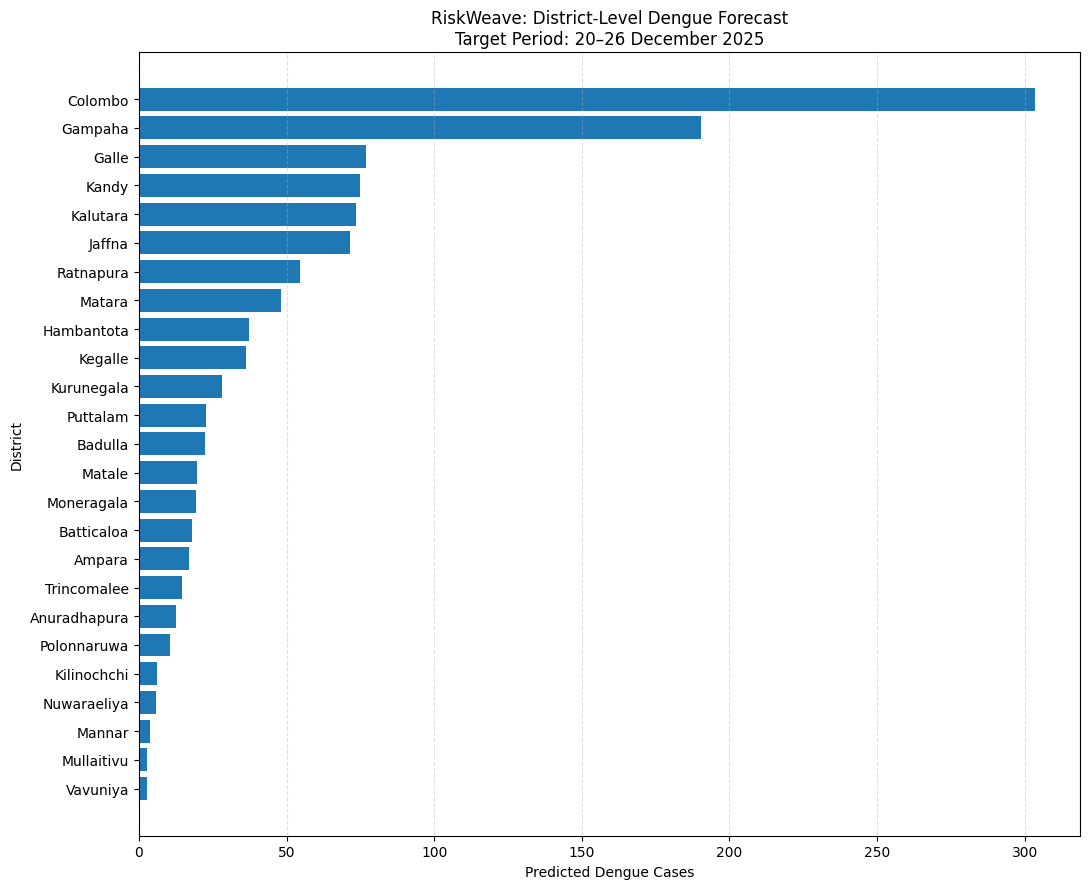

Chart saved to: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\forecasting\district_dengue_forecast.png


In [10]:
import matplotlib.pyplot as plt

# Prepare data for visualization
plot_data = forecast_results.sort_values(
    "predicted_dengue_cases",
    ascending=True
)

plt.figure(figsize=(11, 9))

plt.barh(
    plot_data["district_key"].str.title(),
    plot_data["predicted_dengue_cases"]
)

plt.xlabel("Predicted Dengue Cases")
plt.ylabel("District")

plt.title(
    "RiskWeave: District-Level Dengue Forecast\n"
    "Target Period: 20–26 December 2025"
)

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save chart
CHART_PATH = (
    FORECAST_OUTPUT_DIR / "district_dengue_forecast.png"
)

plt.savefig(CHART_PATH, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", CHART_PATH)

In [11]:
# Create preliminary inspection priority ranking

inspection_priority = forecast_results[
    [
        "district_key",
        "forecast_target_start",
        "forecast_target_end",
        "predicted_dengue_cases"
    ]
].copy()

# Rank districts by predicted dengue cases
inspection_priority["inspection_priority_rank"] = (
    inspection_priority["predicted_dengue_cases"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

inspection_priority = inspection_priority.sort_values(
    "inspection_priority_rank"
).reset_index(drop=True)

print("PRELIMINARY INSPECTION PRIORITY")
print("--------------------------------")

display(inspection_priority)

PRELIMINARY INSPECTION PRIORITY
--------------------------------


,district_key,forecast_target_start,forecast_target_end,predicted_dengue_cases,inspection_priority_rank
0,colombo,2025-12-20,2025-12-26,303.55,1
1,gampaha,2025-12-20,2025-12-26,190.49,2
2,galle,2025-12-20,2025-12-26,76.96,3
3,kandy,2025-12-20,2025-12-26,75.03,4
4,kalutara,2025-12-20,2025-12-26,73.39,5
5,jaffna,2025-12-20,2025-12-26,71.46,6
6,ratnapura,2025-12-20,2025-12-26,54.54,7
7,matara,2025-12-20,2025-12-26,48.07,8
8,hambantota,2025-12-20,2025-12-26,37.36,9
9,kegalle,2025-12-20,2025-12-26,36.22,10


In [12]:
# Save preliminary inspection priority ranking

PRIORITY_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "forecasting"
    / "preliminary_inspection_priority.csv"
)

inspection_priority.to_csv(
    PRIORITY_PATH,
    index=False
)

print("Inspection priority file saved:")
print(PRIORITY_PATH)

Inspection priority file saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\forecasting\preliminary_inspection_priority.csv
